çoklu doğrusal regresyon/ katogorik değerler üzerinden çoklu doğrusal regresyon analizi

In [40]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import seaborn as sns
import matplotlib.pyplot as plt 
import sklearn.metrics as mt

In [26]:
data=sns.load_dataset("tips")
veri=data.copy()
print(veri.head(),veri.isnull().sum(),veri.dtypes)

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4 total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64 total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object


In [30]:
katagori=veri.select_dtypes(include=["category"]).columns
veri=pd.get_dummies(veri,columns=katagori,drop_first=True)
veri


,total_bill,tip,size,sex_Female,smoker_No,day_Fri,day_Sat,day_Sun,time_Dinner
0,16.99,1.01,2,True,True,False,False,True,True
1,10.34,1.66,3,False,True,False,False,True,True
2,21.01,3.50,3,False,True,False,False,True,True
3,23.68,3.31,2,False,True,False,False,True,True
4,24.59,3.61,4,True,True,False,False,True,True
...,...,...,...,...,...,...,...,...,...
239,29.03,5.92,3,False,True,False,True,False,True
240,27.18,2.00,2,True,False,False,True,False,True
241,22.67,2.00,2,False,False,False,True,False,True
242,17.82,1.75,2,False,True,False,True,False,True


kukla değişken tuzağına düşmemk için (drop_first) kullanıyoruz ve her katogori için n-1 elde etmiş oluyoruz

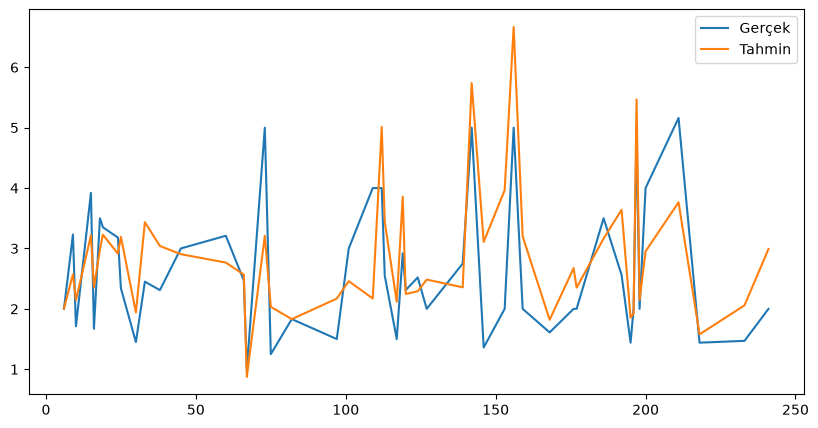

0.4373018194348247


In [42]:
y=veri["tip"]
x=veri.drop(columns="tip")
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)
lr=LinearRegression()
lr.fit(x_train,y_train)
tahmin=lr.predict(x_test)
sonuç=pd.DataFrame({"Gerçek":y_test,"Tahmin":tahmin},index=y_test.index)
sonuç=sonuç.sort_index()
sonuç.plot(kind="line", figsize=(10, 5))
plt.show()
print(mt.r2_score(y_test,tahmin))
